In [101]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings("ignore")

# load the clean data

In [102]:
df=pd.read_csv("../data/proceed/clean_data.csv")
df2=df.copy()

In [103]:
df.head()

,Arrival_Date,Commodity,Grade,Market,Max_Price,Min_Price,Modal_Price,Variety,Year,Month,Day,Day_of_week,Season
0,2023-11-08,Apple,Medium,Bhagta Bhai Ka,3800.0,3800.0,3800.0,Other,2023,11,8,2,Autumn
1,2023-11-08,Banana,Medium,Maur,3400.0,3100.0,3200.0,Banana - Ripe,2023,11,8,2,Autumn
2,2023-11-08,Tomato,FAQ,Bhagta Bhai Ka,2100.0,2100.0,2100.0,Other,2023,11,8,2,Autumn
3,2023-11-08,Banana,Large,Bathinda,1750.0,1550.0,1650.0,Other,2023,11,8,2,Autumn
4,2023-11-08,Tomato,FAQ,Raman,1870.0,1640.0,1740.0,Other,2023,11,8,2,Autumn


* Analysis is completed in previous notebook so the main focus to build a forecasting model don't analysis let's start our journey

# Rolling mean vs Rolling std Report

========== Bhagta Bhai Ka Report ==============


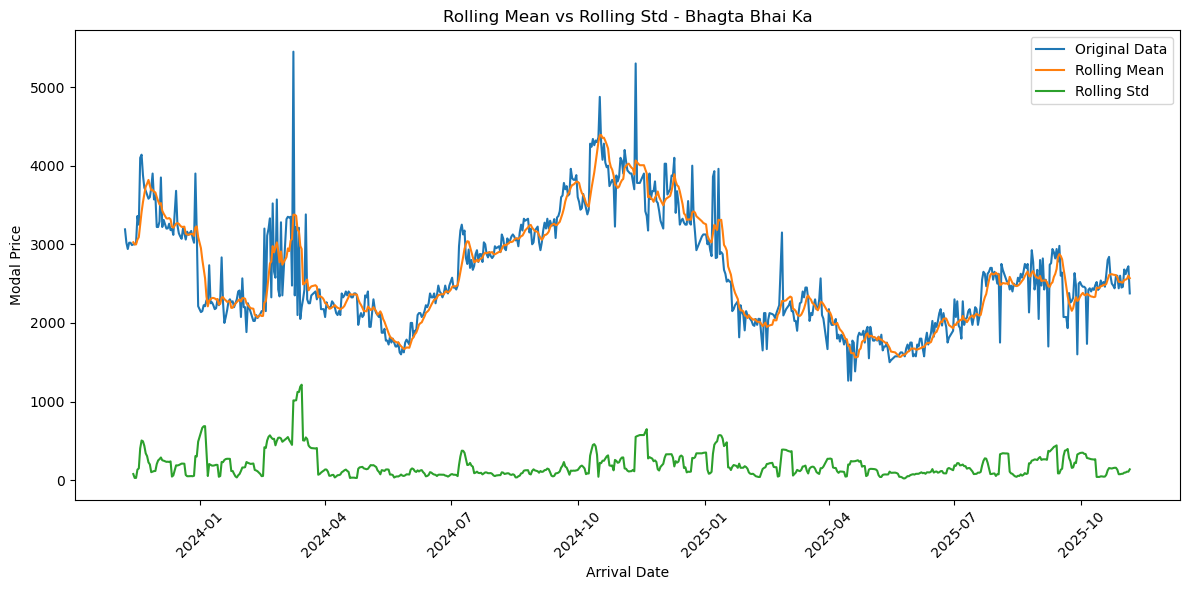

========== Maur Report ==============


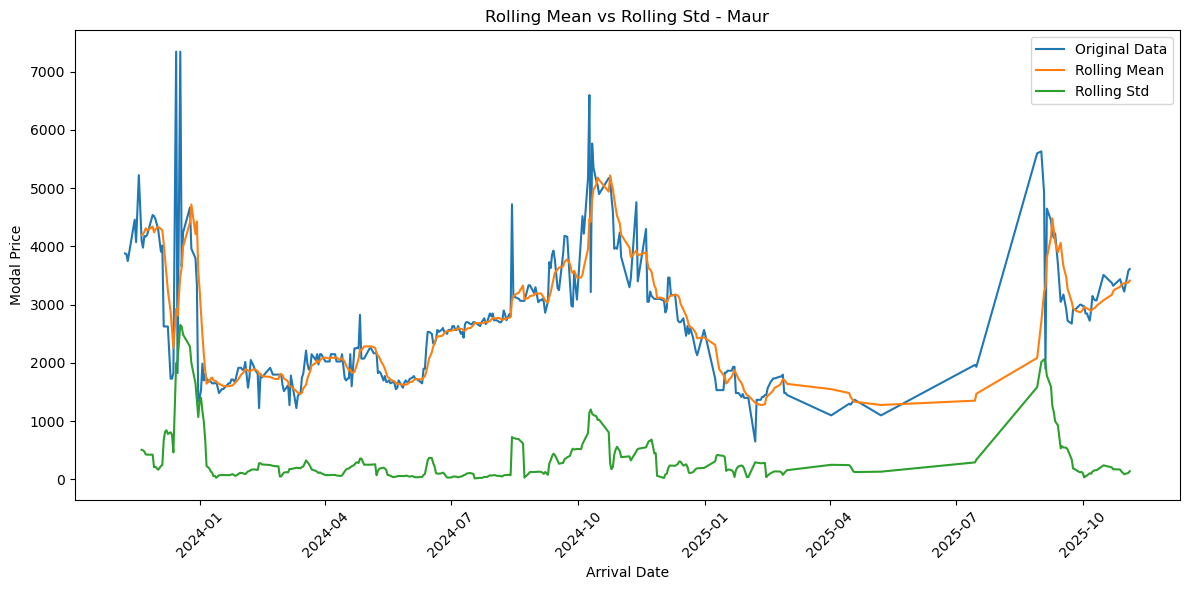

========== Bathinda Report ==============


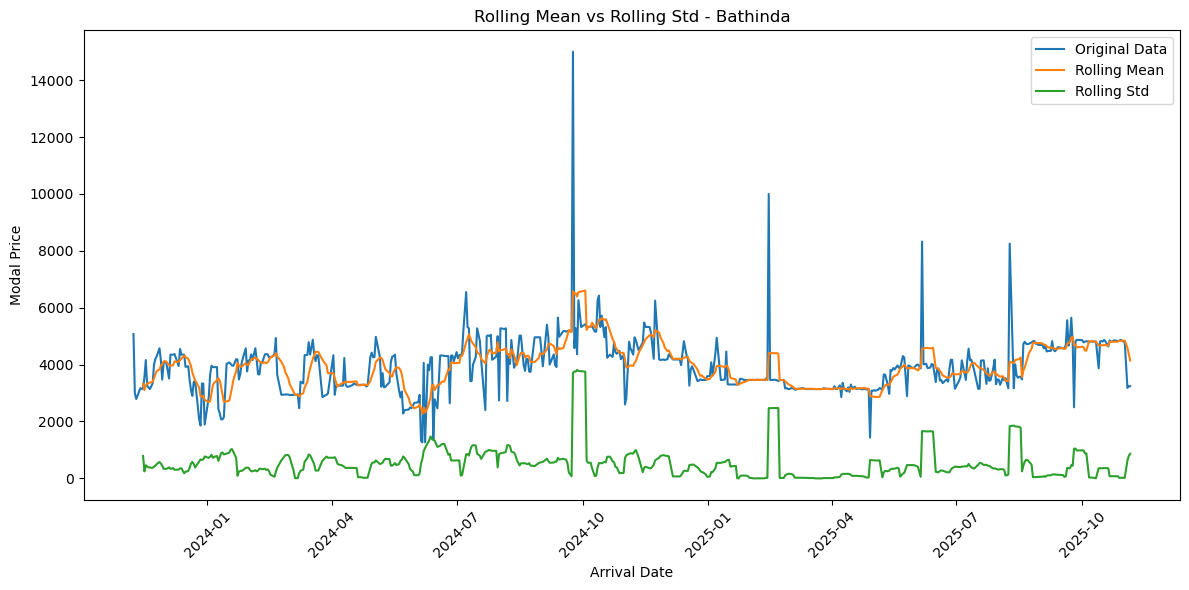

========== Raman Report ==============


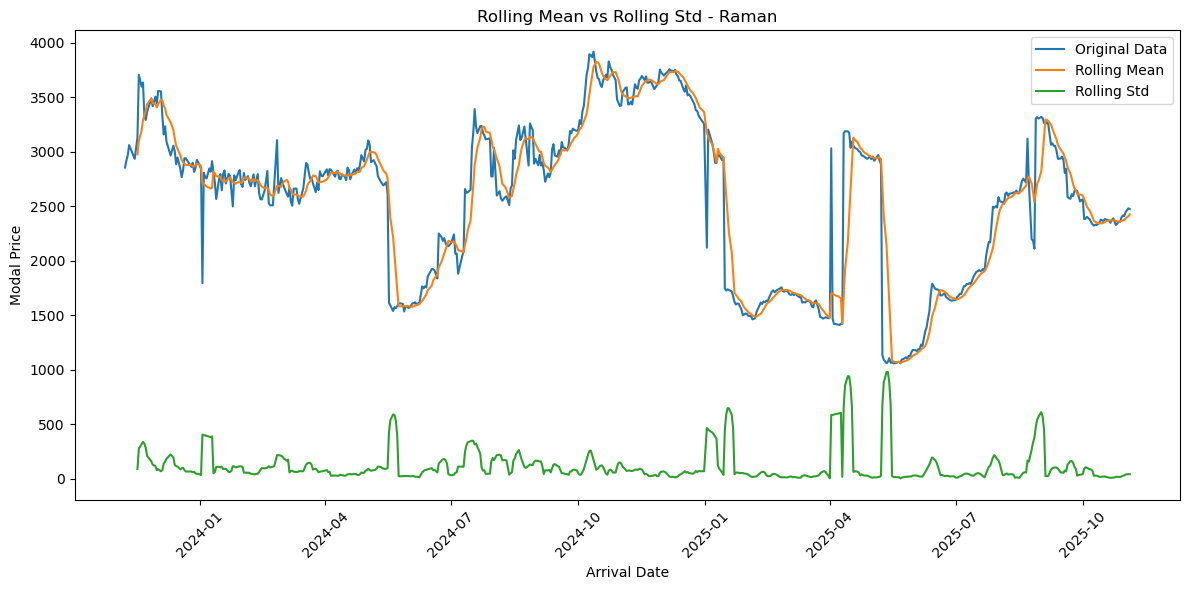

========== Talwandi Sabo Report ==============


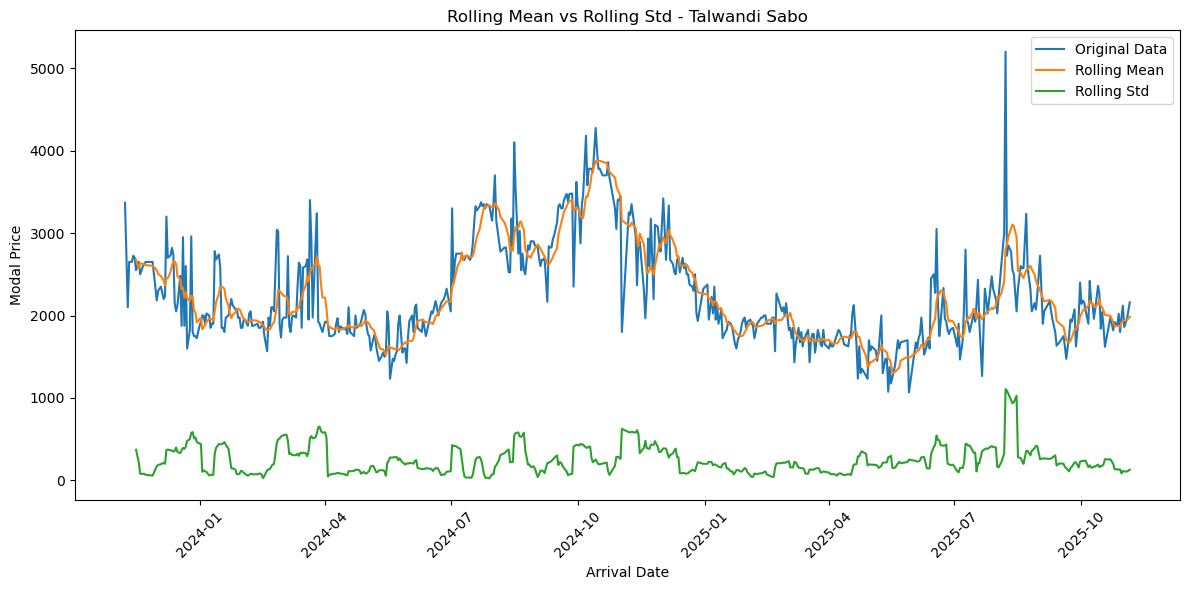

========== Rampuraphul(Nabha Mandi) Report ==============


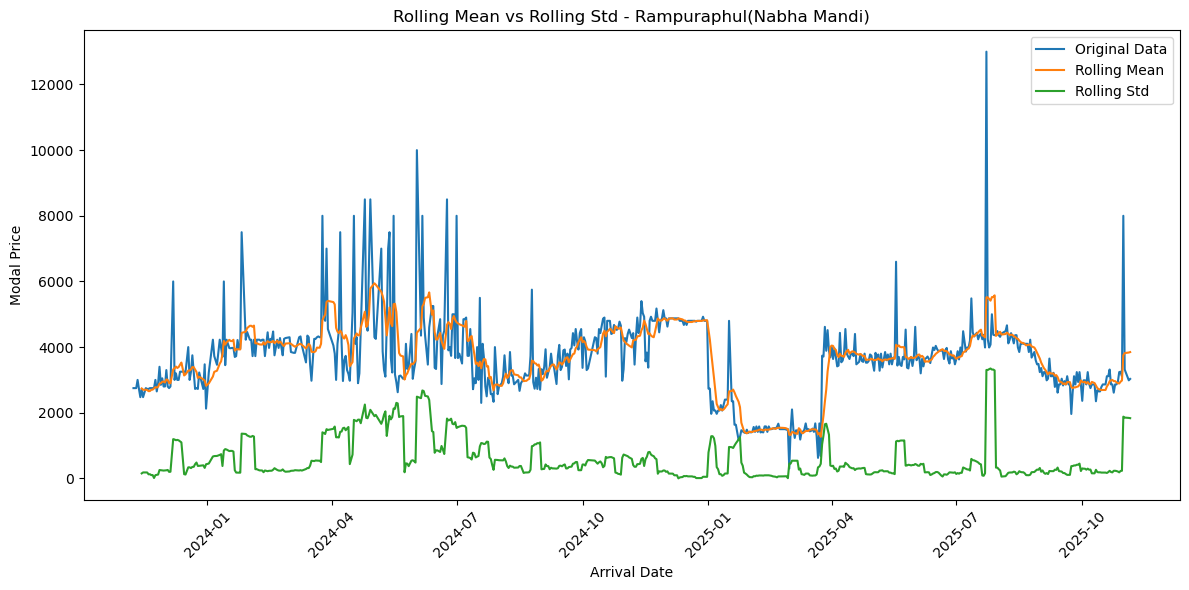

========== Bhucho Report ==============


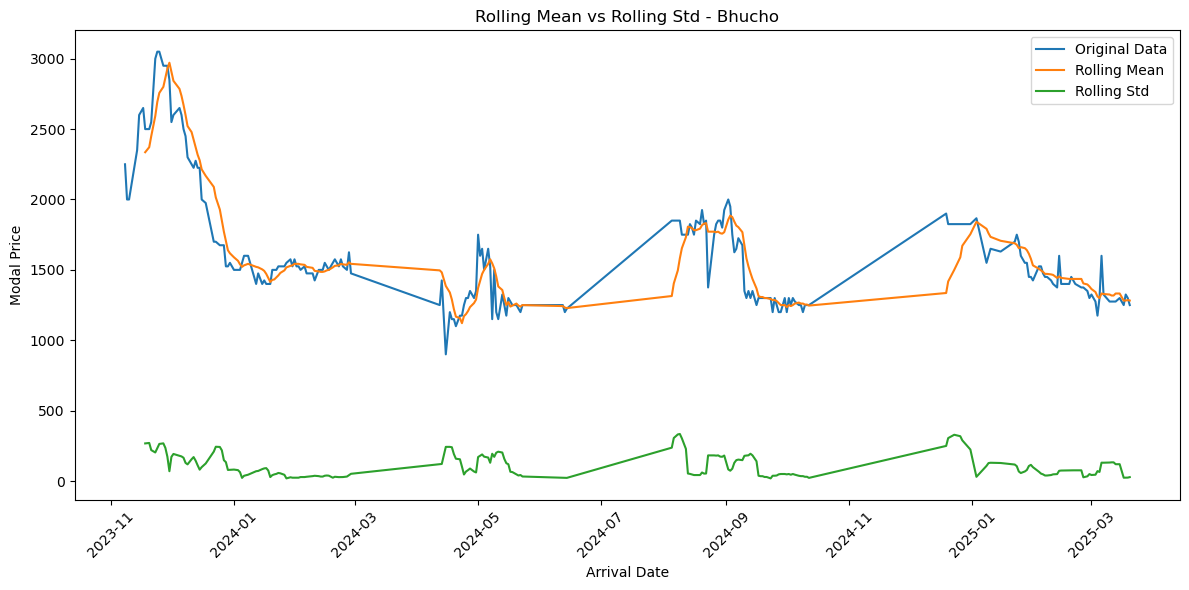

========== Rampura Phul Report ==============


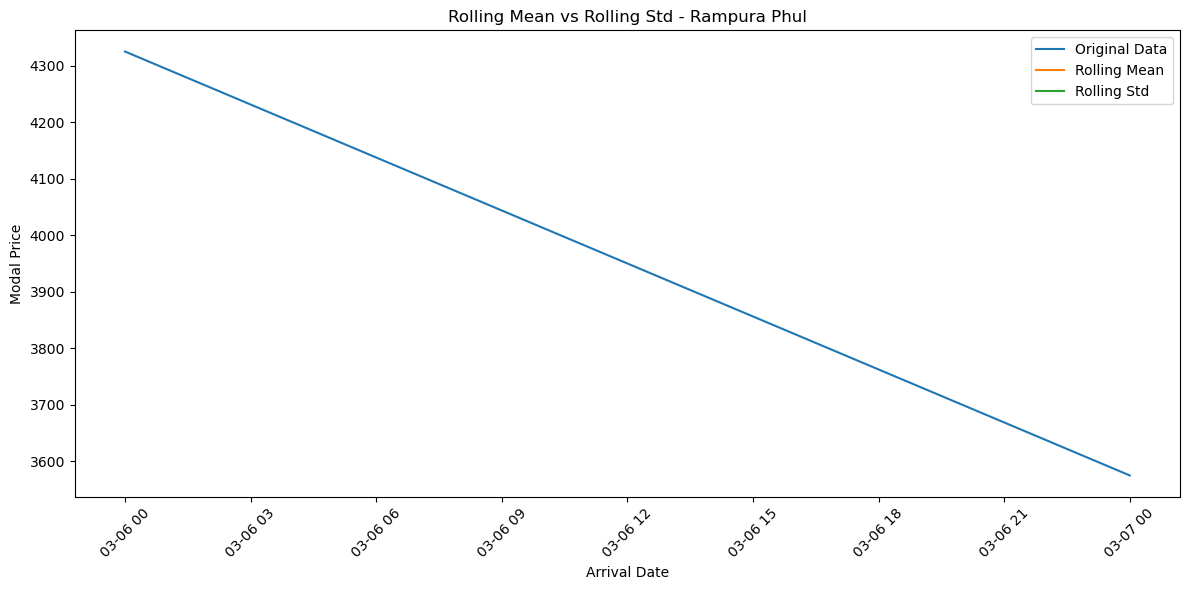

========== Talwandi Sabo APMC Report ==============


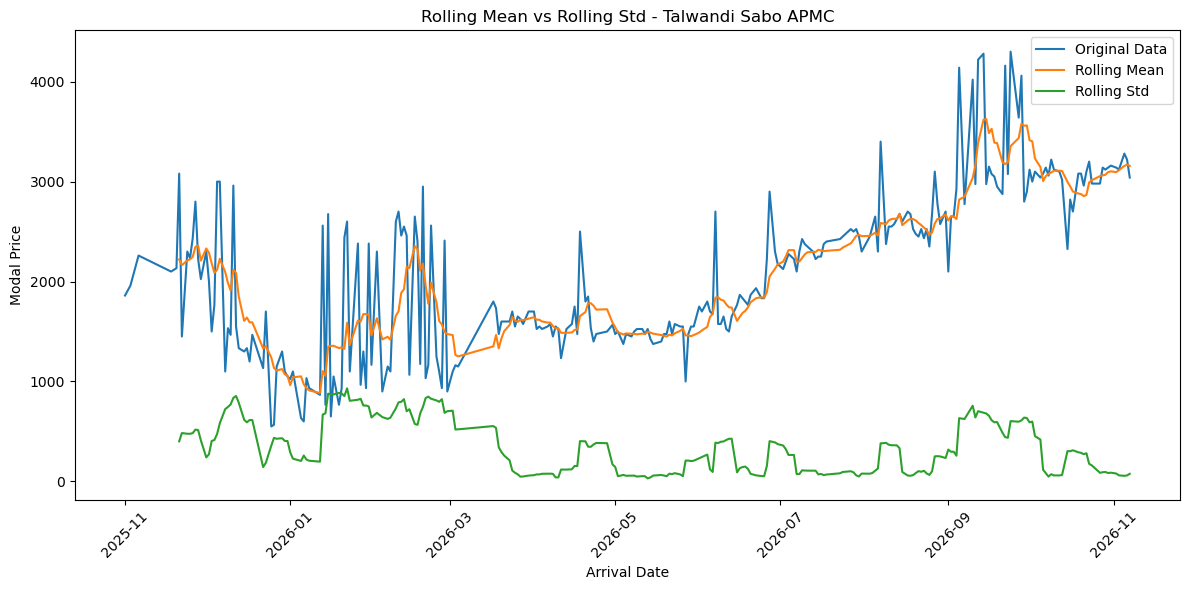

========== Rampuraphul(Nabha Mandi) APMC Report ==============


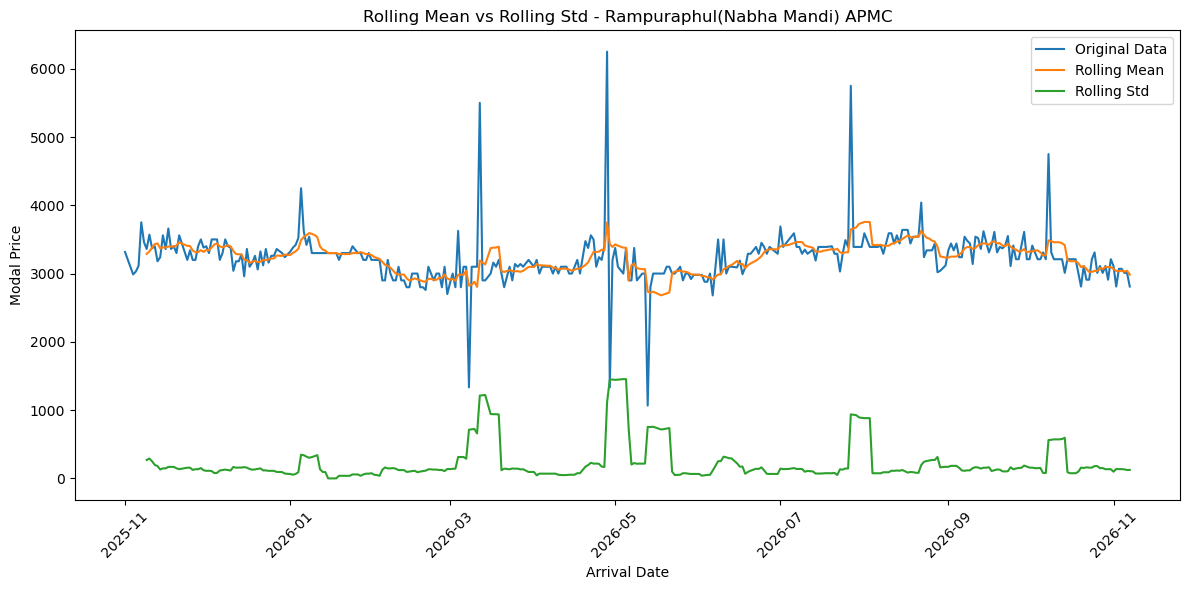

========== Raman APMC Report ==============


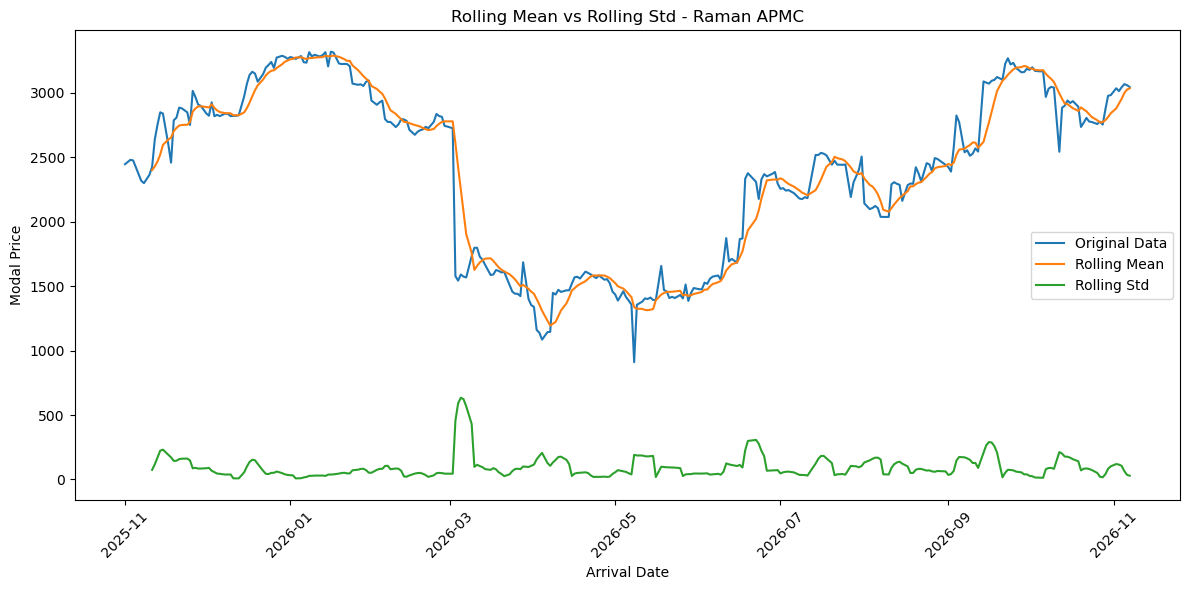

========== Bathinda APMC Report ==============


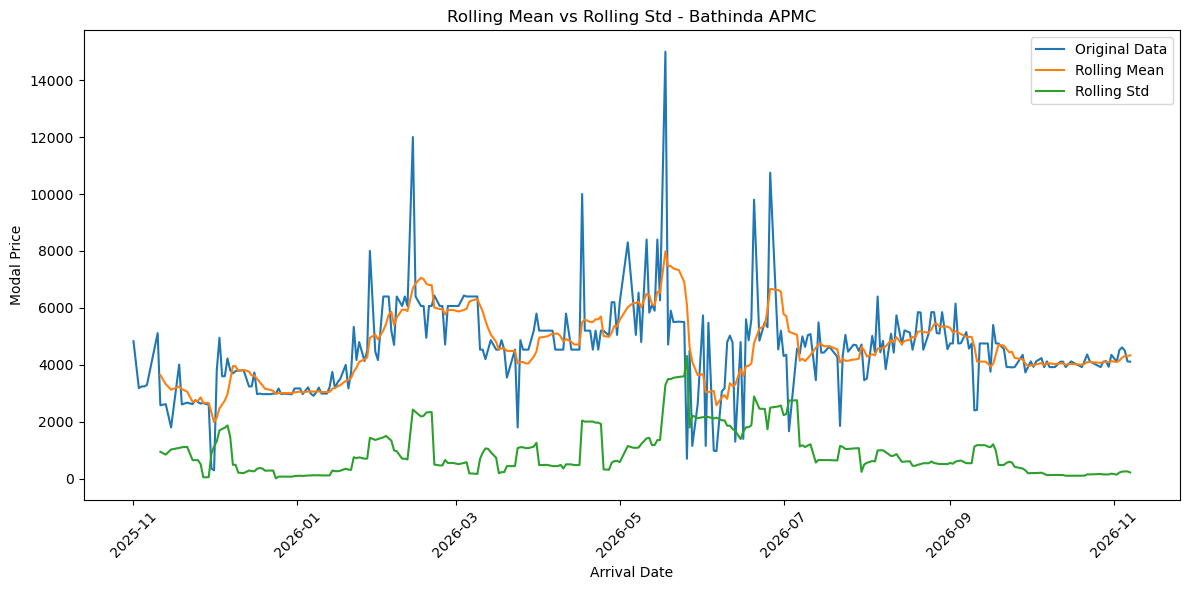

========== Bhagta Bhai Ka APMC Report ==============


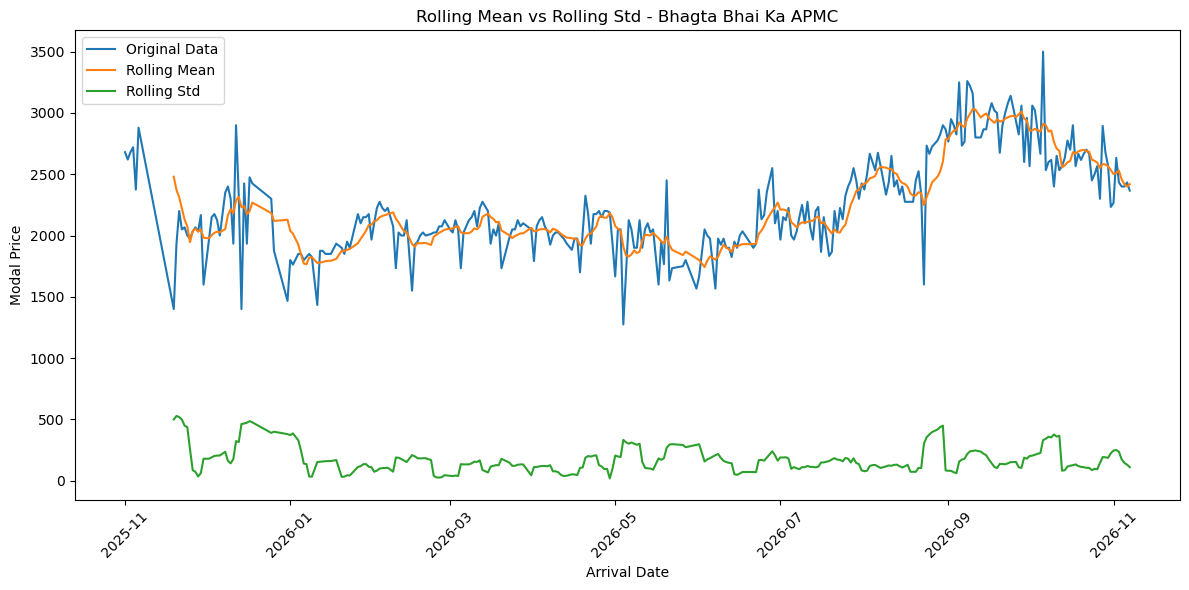

========== Maur APMC Report ==============


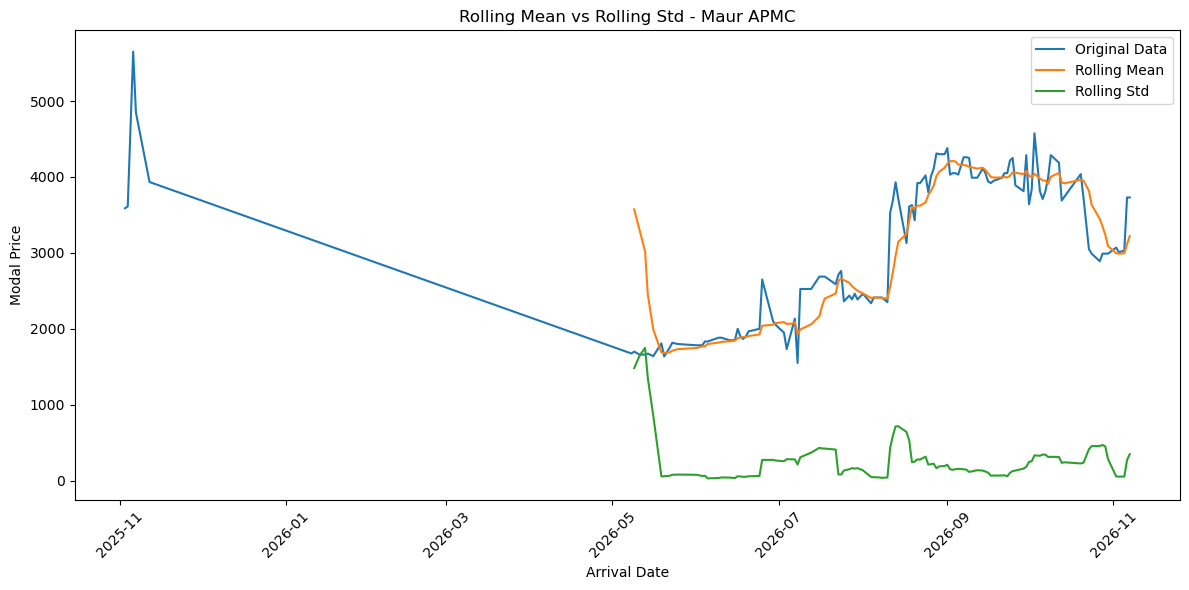

========== Bhucho APMC Report ==============


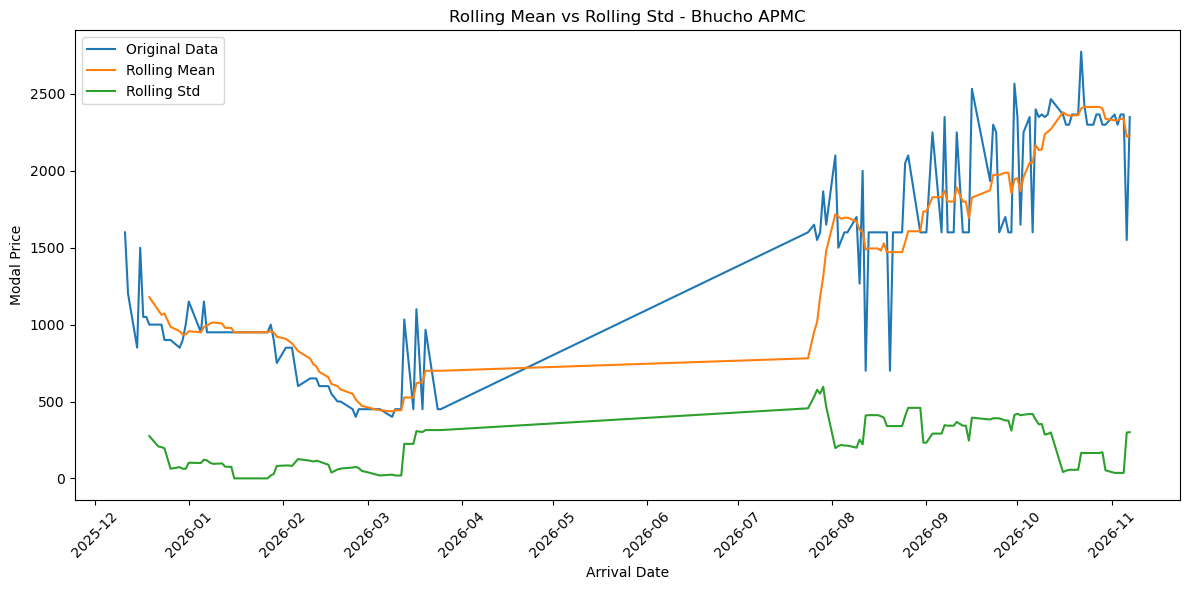

In [104]:

for market in df["Market"].unique():
    print(f"========== {market} Report ==============")

    data = df[df["Market"] == market].copy()

    # Convert Arrival_Date into datetime
    data["Arrival_Date"] = pd.to_datetime(data["Arrival_Date"])

    # Sort by date
    data = data.sort_values("Arrival_Date")


    # Set Arrival_Date as index
    data = data.set_index("Arrival_Date")

    # Group by date and calculate mean
    ts = data.groupby(level=0)["Modal_Price"].mean()

    # Rolling mean and standard deviation
    rolling_mean = ts.rolling(window=7).mean()
    rolling_std = ts.rolling(window=7).std()

    # Visualization
    plt.figure(figsize=(12, 6))

    plt.plot(ts.index, ts, label="Original Data")
    plt.plot(rolling_mean.index, rolling_mean, label="Rolling Mean")
    plt.plot(rolling_std.index, rolling_std, label="Rolling Std")

    plt.xlabel("Arrival Date")
    plt.ylabel("Modal Price")
    plt.xticks(rotation=45)

    plt.legend()
    plt.title(f"Rolling Mean vs Rolling Std - {market}")
    plt.tight_layout()
    plt.show()


In [105]:
# Drop unwanted features that perform data leakage
df.drop(columns=["Arrival_Date","Max_Price","Min_Price","Day"],axis=1,inplace=True)

# 2. Lag Features

### Creating historical price features to capture previous price patterns:

##### Lag_1

##### Lag_7

##### Lag_30

In [106]:
# sort the values
df=df.sort_values(["Commodity","Market","Year","Month"]).copy()

# groupby with commodity and Market

groupby_cols=["Commodity","Market"]

# lag 1 features
df['lag1']=df.groupby(groupby_cols)["Modal_Price"].shift(1)
df['lag7']=df.groupby(groupby_cols)["Modal_Price"].shift(7)
df['lag30']=df.groupby(groupby_cols)["Modal_Price"].shift(30)

# 3. Rolling Statistical Features

### Calculating recent price trends and fluctuations:

###### Rolling_Mean_7

###### Rolling_Mean_30

###### Rolling_Std_7

In [107]:
# rolling features
df["rolling_mean7"]=df.groupby(groupby_cols)["Modal_Price"].transform(lambda x: x.shift(1).rolling(window=7).mean())

# rolling mean 30 
df['rolling_mean30']=df.groupby(groupby_cols)["Modal_Price"].transform(lambda x: x.shift(1).rolling(window=30).mean())

# rolling std of 7 days
df["rolling_std7"]=df.groupby(groupby_cols)["Modal_Price"].transform(lambda x: x.shift(1).rolling(window=7).std())

In [108]:
# drop nan values
df.dropna(inplace=True)


# Chronological Spiliting

In [109]:
split = int(len(df) * 0.80)

X_train = df.iloc[:split].drop(columns=['Modal_Price'])
y_train = df.iloc[:split]['Modal_Price']

X_test = df.iloc[split:].drop(columns=['Modal_Price'])
y_test = df.iloc[split:]['Modal_Price']

In [110]:
print(f"X_train shape:- {X_train.shape}")
print(f"X_test shape:- {X_test.shape}")
print(f"y_train shape:- {y_train.shape}")
print(f"y_test shape:- {y_test.shape}")

X_train shape:- (15658, 14)
X_test shape:- (3915, 14)
y_train shape:- (15658,)
y_test shape:- (3915,)


# Data Preprocessing

In [111]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [112]:
train_num_cols=["Year","Month","Day_of_week"]
train_cat_cols=X_train.select_dtypes(include=[np.number]).columns.tolist()

In [113]:
preprocessor=ColumnTransformer([
    ('encoding',OneHotEncoder(drop="first",handle_unknown="ignore"),train_cat_cols),
    ("num_cols","passthrough",train_num_cols)
])

In [114]:
preprocessor

ColumnTransformer(transformers=[('encoding',
                                 OneHotEncoder(drop='first',
                                               handle_unknown='ignore'),
                                 ['Year', 'Month', 'Day_of_week', 'lag1',
                                  'lag7', 'lag30', 'rolling_mean7',
                                  'rolling_mean30', 'rolling_std7']),
                                ('num_cols', 'passthrough',
                                 ['Year', 'Month', 'Day_of_week'])])

In [115]:
X_train_transform=preprocessor.fit_transform(X_train)
X_test_transform=preprocessor.transform(X_test)

# Distribution:- train & test

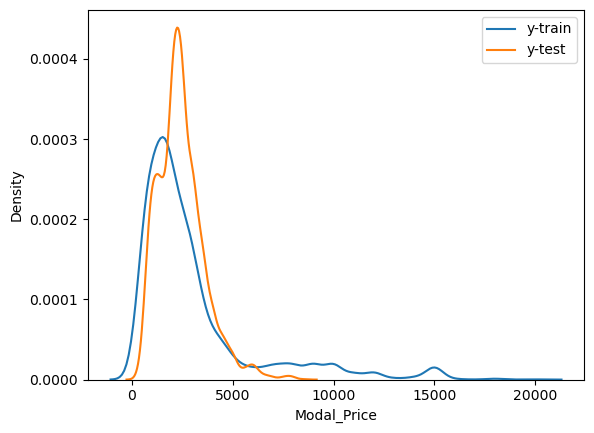

In [116]:
sns.distplot(y_train,hist=False,label="y-train")
sns.distplot(y_test,hist=False,label="y-test")
plt.legend()

# MultiModel Training

In [117]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score
from xgboost import XGBRegressor

# RandomForestRegressor 

In [22]:
rf=RandomForestRegressor(
    n_estimators=500,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features=0.75,
    bootstrap=True,
    random_state=42
)

In [ ]:
# fit the model
rf.fit(X_train_transform,y_train)

In [ ]:
y_pred=rf.predict(X_test_transform)

In [ ]:
print(f"MAE:- {mean_absolute_error(y_test,y_pred)}")
print(f"MSE:- {mean_squared_error(y_test,y_pred)}")
print(f"RMSE:- {root_mean_squared_error(y_test,y_pred)}")
print(f"R2_score:- {r2_score(y_test,y_pred)}")

# Linear Regression

In [118]:
from sklearn.linear_model import LinearRegression,SGDRegressor
from sklearn.preprocessing import StandardScaler,FunctionTransformer

num_cols=X_train.drop(columns=["Month","Day_of_week"],axis=1).select_dtypes(include=[np.number]).columns.tolist()
cat_cols=X_train.select_dtypes(include=["object"]).columns.tolist()

linear_preprocessing = ColumnTransformer([

    # Normal numerical columns
    ('num_cols', StandardScaler(), num_cols),

    # Categorical columns
    ('cat_cols', OneHotEncoder(drop='first'), cat_cols),

    # Month cyclic encoding
    ('month_cyclic',
     FunctionTransformer(lambda x: np.hstack([
         np.sin(2 * np.pi * x / 12),
         np.cos(2 * np.pi * x / 12)
     ])),
     ['Month']),

    # DayOfWeek cyclic encoding
    ('day_cyclic',
     FunctionTransformer(lambda x: np.hstack([
         np.sin(2 * np.pi * x / 7),
         np.cos(2 * np.pi * x / 7)
     ])),
     ['Day_of_week'])
])

# apply preprocessing on data
linear_X_train=linear_preprocessing.fit_transform(X_train)
linear_X_test=linear_preprocessing.transform(X_test)

In [119]:
# apply model
model = SGDRegressor(
    loss="squared_error",
    penalty=None,
    learning_rate="constant",
    eta0=0.001,          # Learning Rate
    max_iter=20000,      # Epochs
    tol=1e-6,
    random_state=42
)

In [ ]:
model.fit(linear_X_train,y_train)

SGDRegressor(eta0=0.001, learning_rate='constant', max_iter=20000, penalty=None,
             random_state=42, tol=1e-06)

In [122]:
linear_pred=model.predict(linear_X_test)

In [ ]:
print(f"MAE:- {mean_absolute_error(y_test,linear_pred)}")
print(f"MSE:- {mean_squared_error(y_test,linear_pred)}")
print(f"RMSE:- {root_mean_squared_error(y_test,linear_pred)}")
print(f"R2_score:- {r2_score(y_test,linear_pred)}")

MAE:- 0.0846091637857642
MSE:- 0.0188425422577762
RMSE:- 0.1372681399953252
R2_score:- 0.8736157537690012


In [ ]:
# check overfitting
train_pred=model.predict(linear_X_train)
test_pred=model.predict(linear_X_test)

# evaluation
print("Train R2:", r2_score(y_train, train_pred))
print("Test R2:", r2_score(y_test, test_pred))

# Training and Testing MAE
print("Train MAE:", mean_absolute_error(y_train, train_pred))
print("Test MAE:", mean_absolute_error(y_test, test_pred))

# Training and Testing RMSE
print("Train RMSE:", np.sqrt(mean_squared_error(y_train, train_pred)))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, test_pred)))


Train R2: 0.9657394329367288
Test R2: 0.8736157537690012
Train MAE: 0.08184256625199952
Test MAE: 0.0846091637857642
Train RMSE: 0.1850961022368411
Test RMSE: 0.1372681399953252


# XGBRegressor Model

In [125]:
xgb = XGBRegressor(
    n_estimators=1200,
    learning_rate=0.03,
    max_depth=5,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1,
    objective="reg:squarederror",
    eval_metric="rmse",
    random_state=42,
    n_jobs=-1
)

In [31]:
# fit the model
xgb.fit(X_train_transform,y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.03, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
             max_leaves=None, min_child_weight=3, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=1200,
             n_jobs=-1, num_parallel_tree=None, ...)

In [32]:
xgb_pred=xgb.predict(X_test_transform)

In [33]:
print(f"MAE:- {mean_absolute_error(y_test,xgb_pred)}")
print(f"MSE:- {mean_squared_error(y_test,xgb_pred)}")
print(f"RMSE:- {root_mean_squared_error(y_test,xgb_pred)}")
print(f"R2_score:- {r2_score(y_test,xgb_pred)}")

MAE:- 506.4851891001656
MSE:- 594422.1170326847
RMSE:- 770.9877541392501
R2_score:- 0.5580524236068659


# selecting the final model

In [126]:
model = SGDRegressor(
    loss="squared_error",
    penalty=None,
    learning_rate="constant",
    eta0=0.001,          # Learning Rate
    max_iter=20000,      # Epochs
    tol=1e-6,
    random_state=42
)

In [ ]:
# fit the model
model.fit(linear_X_train,y_train)

SGDRegressor(eta0=0.001, learning_rate='constant', max_iter=20000, penalty=None,
             random_state=42, tol=1e-06)

In [128]:
y_pred=model.predict(linear_X_test)

# Model Evaluation

In [ ]:
print(f"MAE:- {mean_absolute_error(y_test,y_pred)}")
print(f"MSE:- {mean_squared_error(y_test,y_pred)}")
print(f"RMSE:- {root_mean_squared_error(y_test,y_pred)}")
print(f"r2_score:- {r2_score(y_test,y_pred)}")

MAE:- 254.13016996581985
MSE:- 169987.56236504947
RMSE:- 412.29547943804755
r2_score:- 0.8736157537690012


# Actual vs Predicted Graph

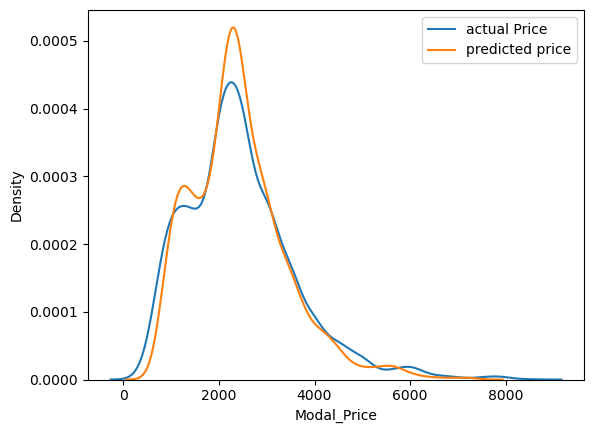

In [ ]:
sns.distplot(y_test,label="actual Price",hist=False)
sns.distplot(y_pred,label="predicted price",hist=False)
plt.legend()

# forecasting

In [132]:

import pandas as pd
import numpy as np


def get_season(date):
    month = date.month

    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Summer'
    elif month in [6, 7, 8, 9]:
        return 'Mansoon'
    else:
        return 'Autumn'


def forecast_price(
    df,
    model,
    y_scaler,
    commodity,
    market,
    start_date,
    end_date,
    last_data_date,
    target='Modal_Price'
):

    # 1. Filter data
    data = df2[
        (df2['Commodity'] == commodity) &
        (df2['Market'] == market)
    ].copy()

    # 2. Sort historical data
    data['Arrival_Date'] = pd.to_datetime(data['Arrival_Date'])
    data = data.sort_values('Arrival_Date').reset_index(drop=True)

    if len(data) < 30:
        raise ValueError("At least 30 historical records required.")

    # 3. Historical prices
    history = data[target].astype(float).tolist()

    # 4. Date validation
    last_data_date = pd.Timestamp(last_data_date)
    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    if data['Arrival_Date'].max() != last_data_date:
        raise ValueError("Last historical date does not match data!")

    if start_date <= last_data_date:
        raise ValueError("Start date must be after last historical date.")

    if end_date < start_date:
        raise ValueError("End date must be after start date.")

    # 5. Future dates
    all_dates = pd.date_range(
        start=last_data_date + pd.Timedelta(days=1),
        end=end_date,
        freq='D'
    )

    last_row = data.iloc[-1].copy()
    results = []

    # 6. Recursive forecasting
    for future_date in all_dates:

        row = last_row.copy()

        # Calendar features
        row['Year'] = future_date.year
        row['Month'] = future_date.month
        row['Day_of_week'] = future_date.dayofweek

        # Automatic Season
        row['Season'] = get_season(future_date)

        # Lag features
        row['lag1'] = history[-1]
        row['lag7'] = history[-7]
        row['lag30'] = history[-30]

        # Rolling features
        row['rolling_mean7'] = np.mean(history[-7:])
        row['rolling_mean30'] = np.mean(history[-30:])
        row['rolling_std7'] = np.std(history[-7:], ddof=1)

        # Model features
        feature_cols = [
            'Commodity', 'Grade', 'Market', 'Variety',
            'Year', 'Month', 'Day_of_week', 'Season',
            'lag1', 'lag7', 'lag30',
            'rolling_mean7', 'rolling_mean30', 'rolling_std7'
        ]

        X_future = pd.DataFrame([row[feature_cols]])

        # Preprocessing
        preprocess_data = linear_preprocessing.transform(X_future)

        # Prediction
        pred_scaled = model.predict(preprocess_data)

        # Inverse scaling
        pred_price = y_scaler.inverse_transform(
            np.asarray(pred_scaled).reshape(-1, 1)
        )[0, 0]

        # Update history
        history.append(pred_price)

        # Save selected dates
        if future_date >= start_date:
            results.append({
                'Forecast_Date': future_date,
                'Commodity': commodity,
                'Market': market,
                'Predicted_Price': pred_price,
                'Season': row['Season'],
                "dayofweek":row["Day_of_week"]
            })

        last_row = row.copy()
        last_row[target] = pred_price

    return pd.DataFrame(results)


In [133]:
forecast = forecast_price(
    df=df,
    model=model,
    y_scaler=scaler,
    commodity='Apple',
    market='Bathinda APMC',
    last_data_date='2026-11-07 ',  # actual last historical date
    start_date='2026-11-08',
    end_date='2026-11-15'
)

print(forecast)

  Forecast_Date Commodity         Market  Predicted_Price  Season  dayofweek
0    2026-11-08     Apple  Bathinda APMC     11588.670824  Autumn          6
1    2026-11-09     Apple  Bathinda APMC     11408.857116  Autumn          0
2    2026-11-10     Apple  Bathinda APMC     11278.708441  Autumn          1
3    2026-11-11     Apple  Bathinda APMC     11097.694681  Autumn          2
4    2026-11-12     Apple  Bathinda APMC     10957.825732  Autumn          3
5    2026-11-13     Apple  Bathinda APMC     10879.312952  Autumn          4
6    2026-11-14     Apple  Bathinda APMC     10763.891096  Autumn          5
7    2026-11-15     Apple  Bathinda APMC     10649.959449  Autumn          6


In [134]:
print("Done")

Done
